# Voting and Stacking

Where bagging and boosting build many copies of *one kind* of model, these two combine **different kinds** of models (logistic regression + KNN + a tree, say). Their errors tend to differ, so combining them beats each one alone.

The base learners are **plugged in from outside** — anything with `fit` / `predict` (and optionally `predict_proba`), from this repo or elsewhere.

## Voting

| | How | Notes |
|---|---|---|
| `hard` | each model votes for a class, majority wins | ignores confidence |
| `soft` | average the predicted probabilities, take the max | one very confident model can outweigh two unsure ones |

## Stacking

Learn *how* to combine, instead of a fixed rule:

1. Split into `cv` folds. For each fold, train every base model on the *other* folds and predict this fold → **out-of-fold** predictions.
2. Train a **meta-model** on `[those predictions → true labels]`.
3. Refit the base models on all data. At prediction time: base predictions → meta-model.

Step 1 is the crucial part: a base model's predictions on rows it was trained on look unrealistically good (a memorizing model looks perfect), so a meta-model trained on them would over-trust it. Out-of-fold predictions are honest. The test suite checks this by spying on the training-set sizes.

Default meta-model is a built-in softmax regression; pass `final_estimator=` to use another.

## Usage

```python
# (the class is defined in the Implementation section below)

base = [("a", ModelA()), ("b", ModelB()), ("c", ModelC())]
vote = VotingClassifier(base, voting="soft").fit(X_train, y_train)
stack = StackingClassifier(base, cv=5).fit(X_train, y_train)
preds = stack.predict(X_test)
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import copy

import numpy as np

# These ensembles COMBINE other models, so the base learners are plugged in from outside: any
# object with fit(X, y) and predict(X), and optionally predict_proba(X) (columns in sorted-class
# order, like scikit-learn). Pass models from this repo or from anywhere else.


def _probabilities(model, X, classes):
    """(n_samples, n_classes) probabilities; a model without predict_proba casts a one-hot vote."""
    if hasattr(model, "predict_proba"):
        return np.asarray(model.predict_proba(X))
    return (np.asarray(model.predict(X))[:, None] == classes[None, :]).astype(float)


class VotingClassifier:
    """Train several different models on the same data and let them vote.

    voting="hard": each model casts one vote for its predicted class; majority wins.
    voting="soft": average the models' predicted probabilities; highest average wins. Soft voting
                   uses each model's confidence, so one very sure model can outweigh two unsure ones."""

    def __init__(self, estimators, voting="hard"):
        self.estimators = estimators  # list of (name, unfitted_model)
        self.voting = voting

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_ = np.unique(y)
        self.models_ = [copy.deepcopy(est).fit(X, y) for _, est in self.estimators]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        if self.voting == "soft":
            avg = np.mean([_probabilities(m, X, self.classes_) for m in self.models_], axis=0)
            return self.classes_[avg.argmax(axis=1)]
        # hard: count how many models chose each class
        picks = np.array([np.searchsorted(self.classes_, m.predict(X)) for m in self.models_])
        counts = np.array([np.bincount(col, minlength=len(self.classes_)) for col in picks.T])
        return self.classes_[counts.argmax(axis=1)]


class _Softmax:
    """Default meta-learner: multiclass logistic regression by gradient descent."""

    def __init__(self, lr=0.5, n_iters=1000):
        self.lr, self.n_iters = lr, n_iters

    def fit(self, X, y):
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        Y = np.eye(len(self.classes_))[y_enc]
        self.W, self.b = np.zeros((X.shape[1], Y.shape[1])), np.zeros(Y.shape[1])
        for _ in range(self.n_iters):
            Z = X @ self.W + self.b
            P = np.exp(Z - Z.max(axis=1, keepdims=True))
            P /= P.sum(axis=1, keepdims=True)
            self.W -= self.lr * X.T @ (P - Y) / len(X)
            self.b -= self.lr * (P - Y).mean(axis=0)
        return self

    def predict(self, X):
        return self.classes_[(X @ self.W + self.b).argmax(axis=1)]


class StackingClassifier:
    """Instead of a fixed vote, LEARN how to combine the base models.

    1. Split the data into `cv` folds. For each fold, train every base model on the other folds
       and predict this fold. These out-of-fold predictions become the meta-features.
    2. Train a final (meta) model on [meta-features -> true labels].
    3. Refit the base models on ALL the data; at prediction time their outputs feed the meta model.

    Out-of-fold predictions are essential: if the meta model were trained on predictions the base
    models made for rows they were trained on, it would learn to over-trust whichever base model
    memorizes best.

    Assumes every training fold contains every class (use plenty of data per class, small cv)."""

    def __init__(self, estimators, final_estimator=None, cv=5, random_state=0):
        self.estimators = estimators
        self.final_estimator = final_estimator
        self.cv = cv
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        n, k = len(X), len(self.classes_)

        folds = np.array_split(np.random.default_rng(self.random_state).permutation(n), self.cv)
        meta = np.zeros((n, k * len(self.estimators)))
        for held_out in folds:
            train = np.setdiff1d(np.arange(n), held_out)
            for j, (_, est) in enumerate(self.estimators):
                model = copy.deepcopy(est).fit(X[train], y[train])
                meta[held_out, j * k:(j + 1) * k] = _probabilities(model, X[held_out], self.classes_)

        self.models_ = [copy.deepcopy(est).fit(X, y) for _, est in self.estimators]
        self.final_estimator_ = copy.deepcopy(self.final_estimator or _Softmax()).fit(meta, y)
        return self

    def _meta_features(self, X):
        return np.hstack([_probabilities(m, X, self.classes_) for m in self.models_])

    def predict(self, X):
        return self.final_estimator_.predict(self._meta_features(np.asarray(X, dtype=float)))

## See it work

### 1. Different models make different mistakes

Three different base learners on noisy moons: a logistic regression (straight boundary), a kNN and a decision tree. Each has its own boundary shape and its own error pattern.

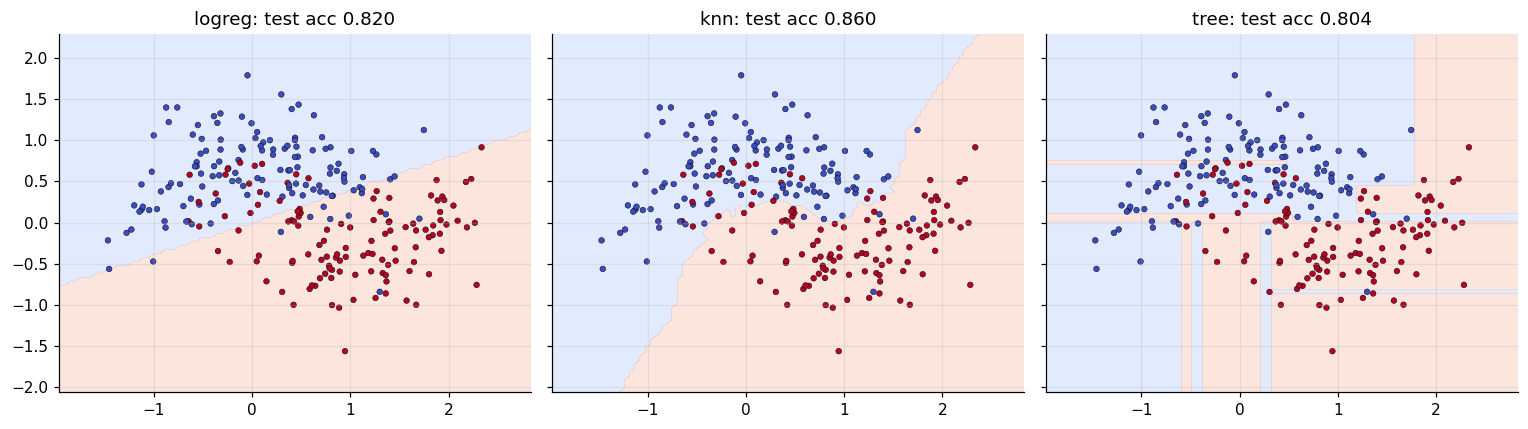

In [3]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression as SkLR
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
def plot_boundary(ax, model, X, y, cmap="coolwarm", n=150, pad=0.5):
    """Colour the plane by the model's predicted class, then draw the data on top."""
    gx, gy = np.meshgrid(np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, n), np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, n))
    pred = np.asarray(model.predict(np.c_[gx.ravel(), gy.ravel()])).reshape(gx.shape)
    K = len(np.unique(y))
    ax.contourf(gx, gy, pred, alpha=0.25, cmap=cmap, levels=np.arange(-0.5, K + 0.5) if K > 2 else [-0.5, 0.5, 1.5])
    ax.scatter(*X.T, c=y, cmap=cmap, s=14, edgecolor="k", linewidth=0.3)

Xm, ym = make_moons(n_samples=500, noise=0.35, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.5, random_state=0)
acc = lambda m, X, y: (m.predict(X) == y).mean()
base = [("logreg", SkLR()), ("knn", KNeighborsClassifier(15)), ("tree", DecisionTreeClassifier(max_depth=6, random_state=0))]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, est) in zip(axes, base):
    est.fit(Xtr, ytr); plot_boundary(ax, est, Xtr, ytr, n=90); ax.set_title(f"{name}: test acc {acc(est, Xte, yte):.3f}")
plt.tight_layout(); plt.show()

### 2. Voting and stacking vs the individual models

- **Hard voting**: majority of predicted labels.
- **Soft voting**: average the predicted probabilities, so confident models count more.
- **Stacking**: learn *how much to trust each model*: the base models' out-of-fold probabilities become the features of a small second-level model.

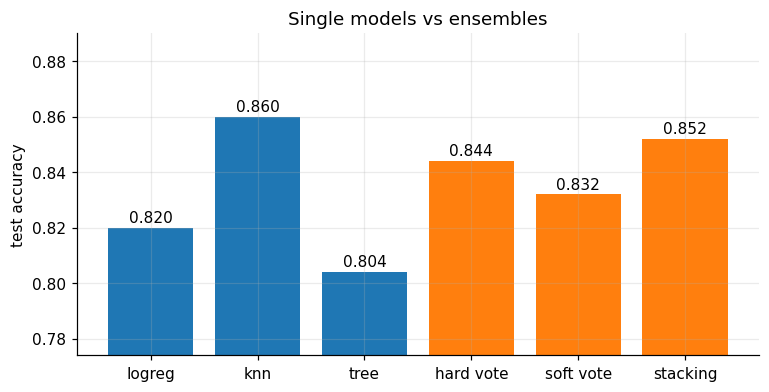

In [4]:
hard = VotingClassifier(base, voting="hard").fit(Xtr, ytr)
soft = VotingClassifier(base, voting="soft").fit(Xtr, ytr)
stack = StackingClassifier(base).fit(Xtr, ytr)
names = [n for n, _ in base] + ["hard vote", "soft vote", "stacking"]
accs = [acc(est, Xte, yte) for _, est in base] + [acc(hard, Xte, yte), acc(soft, Xte, yte), acc(stack, Xte, yte)]
plt.figure(figsize=(8, 3.8)); bars = plt.bar(names, accs, color=["C0"] * 3 + ["C1"] * 3)
for b, a in zip(bars, accs): plt.text(b.get_x() + b.get_width() / 2, a + 0.002, f"{a:.3f}", ha="center")
plt.ylim(min(accs) - 0.03, max(accs) + 0.03); plt.ylabel("test accuracy"); plt.title("Single models vs ensembles"); plt.show()

### 3. Why stacking uses out-of-fold predictions

If the meta-model were trained on the base models' predictions for the *same* data they were fitted on, a model that memorised its training set (like a deep tree) would look perfect and get all the trust. `StackingClassifier` therefore builds meta-features from `cv`-fold **out-of-fold** predictions. Training accuracy of each base model vs its honest (held-out) accuracy:

In [5]:
from sklearn.model_selection import cross_val_score
deep = DecisionTreeClassifier(random_state=0)
print(f"deep tree: accuracy on its own training data = {(deep.fit(Xtr, ytr).predict(Xtr) == ytr).mean():.3f}   cross-validated = {cross_val_score(DecisionTreeClassifier(random_state=0), Xtr, ytr, cv=5).mean():.3f}")
print("-> the in-sample number is useless for deciding how much to trust the tree.")

deep tree: accuracy on its own training data = 1.000   cross-validated = 0.828
-> the in-sample number is useless for deciding how much to trust the tree.


## Check against a reference implementation

The base learners are scikit-learn models plugged in from outside. Our voting/stacking wrappers must agree with scikit-learn's wrappers around the same models.

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import StackingClassifier as SklearnStacking
from sklearn.ensemble import VotingClassifier as SklearnVoting
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.3, random_state=42)

# the base learners are plugged in from outside: here three different scikit-learn models
base = [
    ("logreg", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))),
    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(7))),
    ("tree", DecisionTreeClassifier(max_depth=4, random_state=0)),
]
acc = lambda model: (model.predict(X_test) == y_test).mean()

for name, model in base:
    print("alone  %-7s %.4f" % (name, acc(model.fit(X_train, y_train))))

for voting in ("hard", "soft"):
    ours = VotingClassifier(base, voting=voting).fit(X_train, y_train)
    theirs = SklearnVoting(base, voting=voting).fit(X_train, y_train)
    print("%s voting:    ours=%.4f sklearn=%.4f" % (voting, acc(ours), acc(theirs)))
    assert abs(acc(ours) - acc(theirs)) < 0.01

ours = StackingClassifier(base, cv=5).fit(X_train, y_train)
theirs = SklearnStacking(base, cv=5).fit(X_train, y_train)
print("stacking:     ours=%.4f sklearn=%.4f" % (acc(ours), acc(theirs)))
assert abs(acc(ours) - acc(theirs)) < 0.03

alone  logreg  0.9825
alone  knn     0.9591
alone  tree    0.9474


hard voting:    ours=0.9883 sklearn=0.9883


soft voting:    ours=0.9766 sklearn=0.9766


stacking:     ours=0.9825 sklearn=0.9883


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


class Fixed:
    """Stub model: ignores the data and always answers the same."""

    def __init__(self, label=None, proba=None):
        self.label, self.proba = label, proba

    def fit(self, X, y):
        return self

    def predict(self, X):
        return np.full(len(X), self.label)

    def predict_proba(self, X):
        return np.tile(self.proba, (len(X), 1))


class Centroid:
    """Small real learner: nearest class mean, with probabilities from distances."""

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.means = np.array([X[y == c].mean(axis=0) for c in self.classes_])
        return self

    def predict_proba(self, X):
        d = ((X[:, None] - self.means[None]) ** 2).sum(-1)
        e = np.exp(-d + d.min(axis=1, keepdims=True))
        return e / e.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


def _blobs(seed=0):
    rng = np.random.default_rng(seed)
    X = np.vstack([rng.normal(-2, 1, (60, 2)), rng.normal(2, 1, (60, 2))])
    return X, np.array([0] * 60 + [1] * 60)


def test_hard_voting_is_majority():
    X = np.zeros((4, 1))
    votes = [("a", Fixed(1)), ("b", Fixed(1)), ("c", Fixed(0))]
    model = VotingClassifier(votes, voting="hard").fit(X, np.array([0, 1, 0, 1]))
    assert (model.predict(X) == 1).all()


def test_soft_voting_can_overrule_the_majority():
    # two models mildly prefer class 1, one is very sure about class 0: hard says 1, soft says 0
    X = np.zeros((3, 1))
    y = np.array([0, 1, 0])
    stubs = [("a", Fixed(0, [0.9, 0.1])), ("b", Fixed(1, [0.4, 0.6])), ("c", Fixed(1, [0.4, 0.6]))]
    assert (VotingClassifier(stubs, voting="hard").fit(X, y).predict(X) == 1).all()
    assert (VotingClassifier(stubs, voting="soft").fit(X, y).predict(X) == 0).all()


def test_stacking_uses_out_of_fold_data():
    class Spy(Centroid):
        sizes = []

        def fit(self, X, y):
            Spy.sizes.append(len(X))
            return super().fit(X, y)

    X, y = _blobs()
    StackingClassifier([("spy", Spy())], cv=5).fit(X, y)
    # five fits on 80% of the data (the out-of-fold ones), then one refit on everything
    assert Spy.sizes == [96] * 5 + [120]


def test_stacking_learns_to_trust_the_good_model():
    X, y = _blobs(1)
    model = StackingClassifier([("good", Centroid()), ("useless", Fixed(0, [0.5, 0.5]))]).fit(X, y)
    X_new, y_new = _blobs(2)
    assert (model.predict(X_new) == y_new).mean() > 0.9

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_hard_voting_is_majority
PASS test_soft_voting_can_overrule_the_majority
PASS test_stacking_uses_out_of_fold_data
PASS test_stacking_learns_to_trust_the_good_model

all 4 tests passed


## Takeaways

- **Use it** to squeeze a few more points out of a set of **diverse** good models (different families beat many similar ones). Always compare against the best single model; sometimes the ensemble does not help.
- **Voting:** simplest and hardest to overfit. **Stacking:** more powerful, can overfit, needs out-of-fold meta-features and a simple meta-model.
- **Cost:** you train and serve every model.
- **Interview line:** *"Combine diverse models: vote or average probabilities, or train a meta-learner on out-of-fold predictions (never in-sample ones, which leak)."*